# 8. 2D Silicon Nanowire Array for Photovoltaics: Efficiency and Dispersion

## Physical Motivation & Learning Objectives
Silicon nanowire arrays enhance solar cell light trapping through localized optical resonances and subwavelength scattering. In this tutorial:
1. We simulate a 2D square array of vertical silicon nanowires.
2. We compute photovoltaic figures of merit: short-circuit current density $J_{\mathrm{sc}}$ and ultimate efficiency $\eta$ under AM1.5G solar illumination.
3. We plot the modal dispersion diagram (`plotting.omega_plot`).

> [!NOTE]
> **Meshing Workflow: Classic Gmsh / Pre-Generated Mesh (`examples/`)**
> This notebook uses EMUstack's classic meshing workflow (`make_mesh_now=True, lc_bkg=0.1, lc2=2.0` or loading pre-generated `.mail` meshes from `EMUstack/backend/data/meshes/`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import concurrent.futures

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Nanowire Array Parameters


In [2]:
wavelengths = np.linspace(400, 1000, 5)
period = 600.0        # nm
NW_diameter = 120.0   # nm

light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Si_c, loss=True)

NW_array = objects.NanoStruct(
    '2D_array', period, NW_diameter,
    height_nm=2330.0,
    inclusion_a=materials.Si_c,
    background=materials.Air,
    loss=True,
    make_mesh_now=True, lc_bkg=0.1, lc2=2.0,
    plt_msh=False
)

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    sim_nw  = NW_array.calc_modes(light, num_BMs=30)
    stk = Stack((sim_sub, sim_nw, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

with concurrent.futures.ThreadPoolExecutor() as executor:
    stacks_list = list(executor.map(simulate_stack, light_list))


 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.
 substrate therefore cannot calculate energy fluxes here.
 superstrate therefore CANNOT CALCULATE ENERGY FLUXES ANYWHERE.


## Photovoltaic Figures of Merit: $J_{\mathrm{sc}}$ and Ultimate Efficiency $\eta$


Spectra and Photovoltaic Metrics evaluated successfully.
<ipython-input-1-11862fa2c58f>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


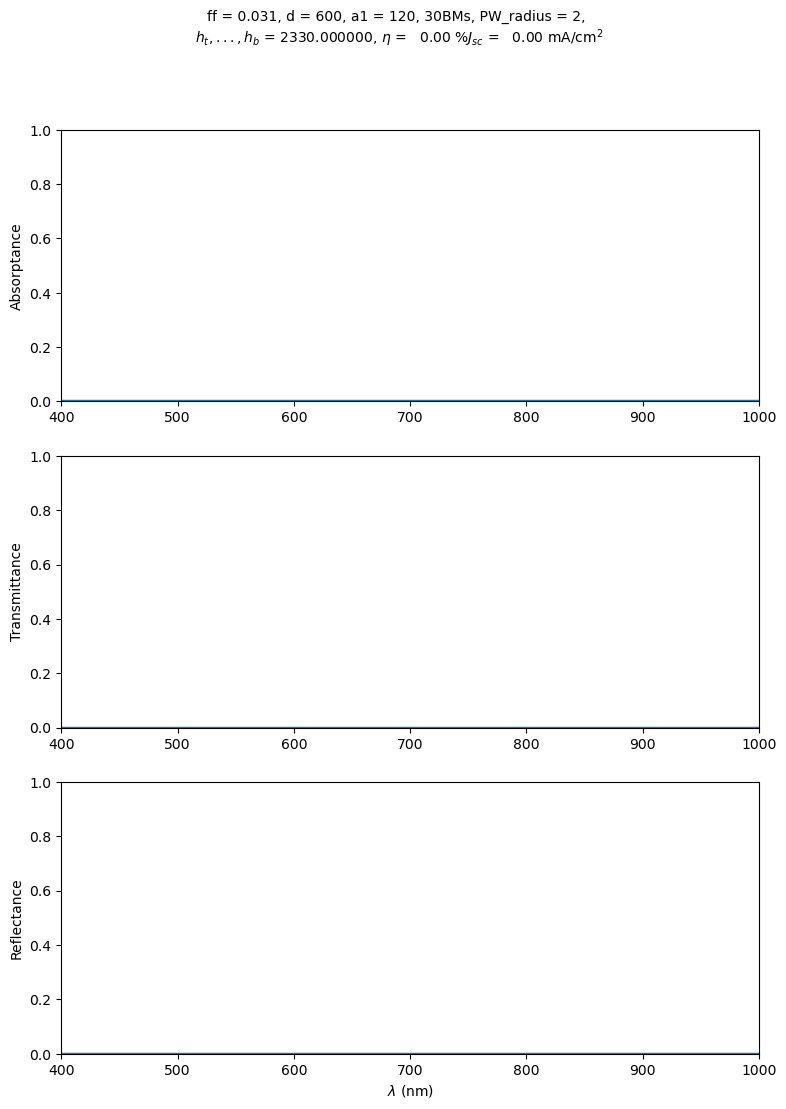

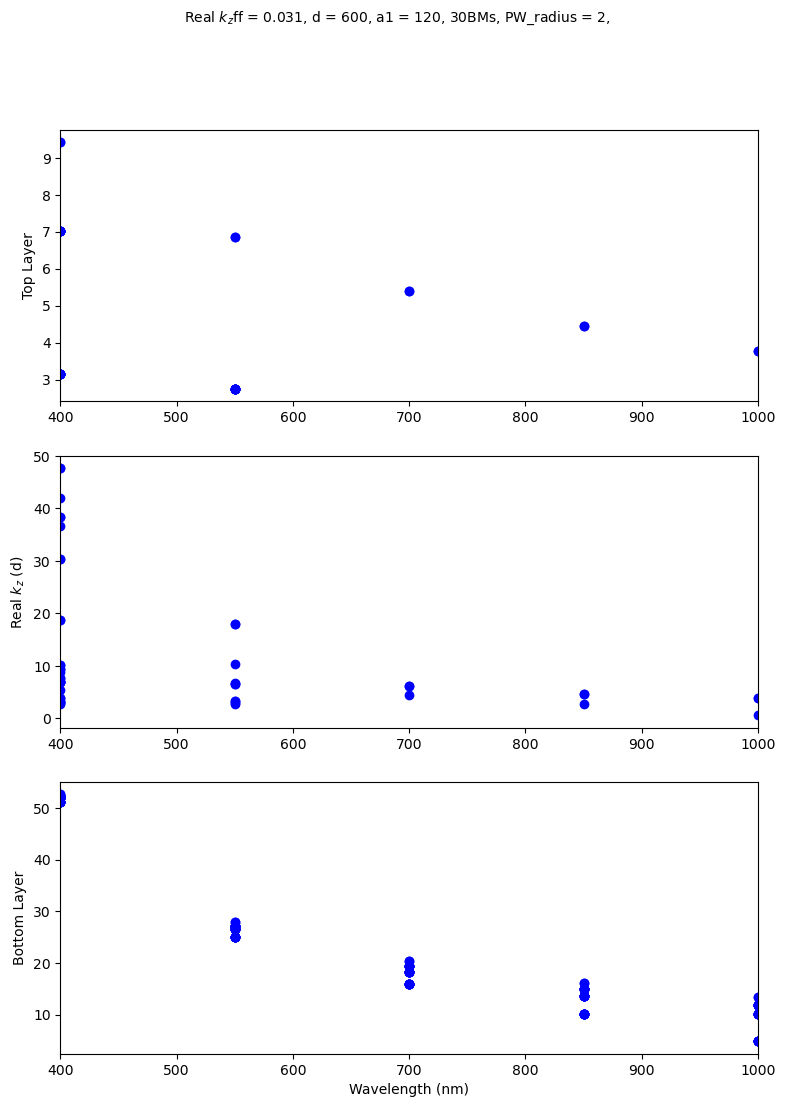

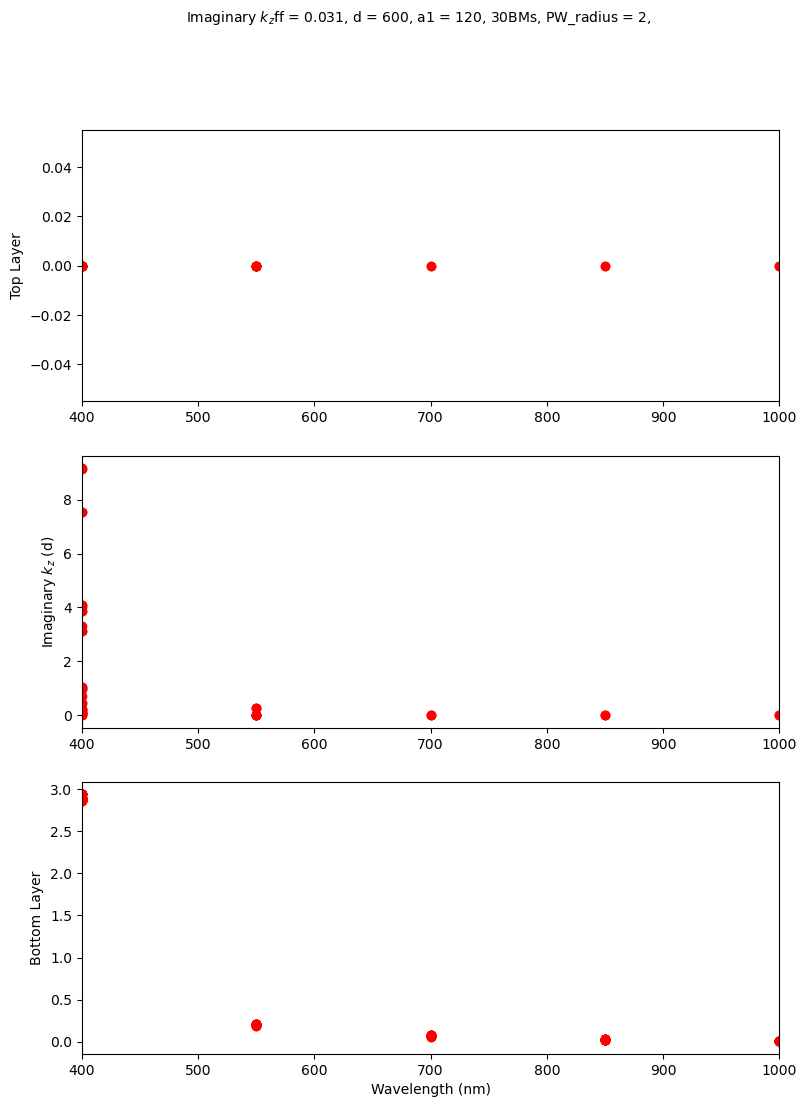

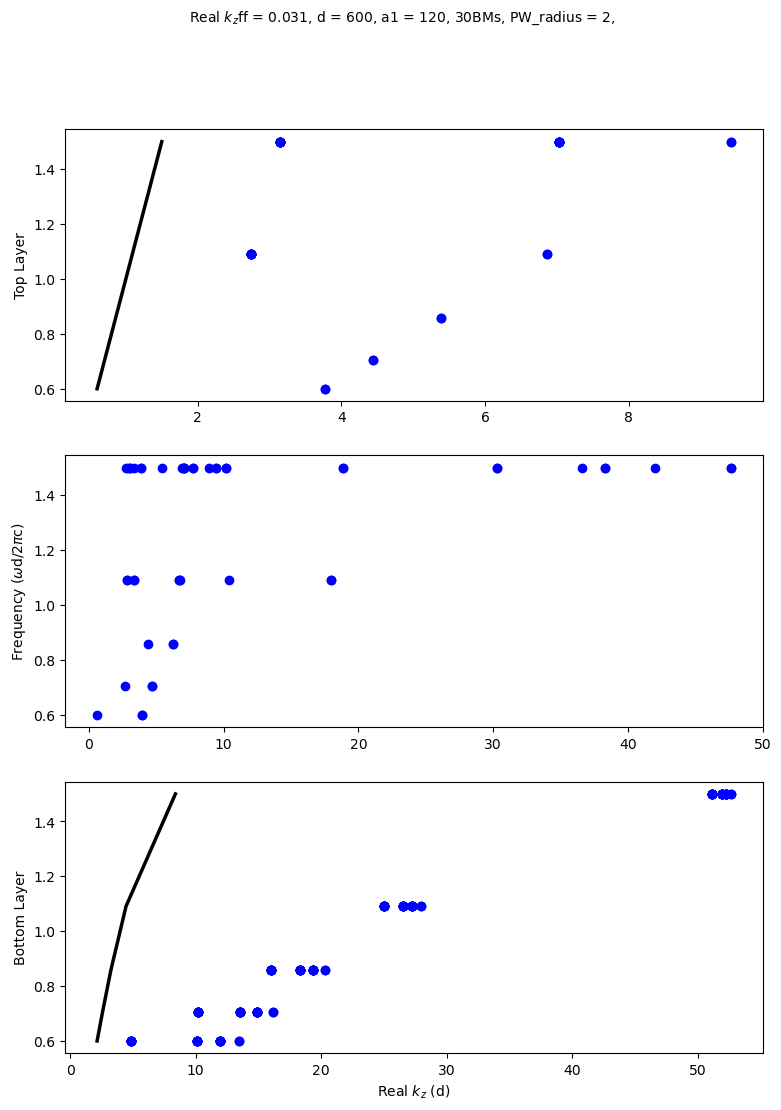

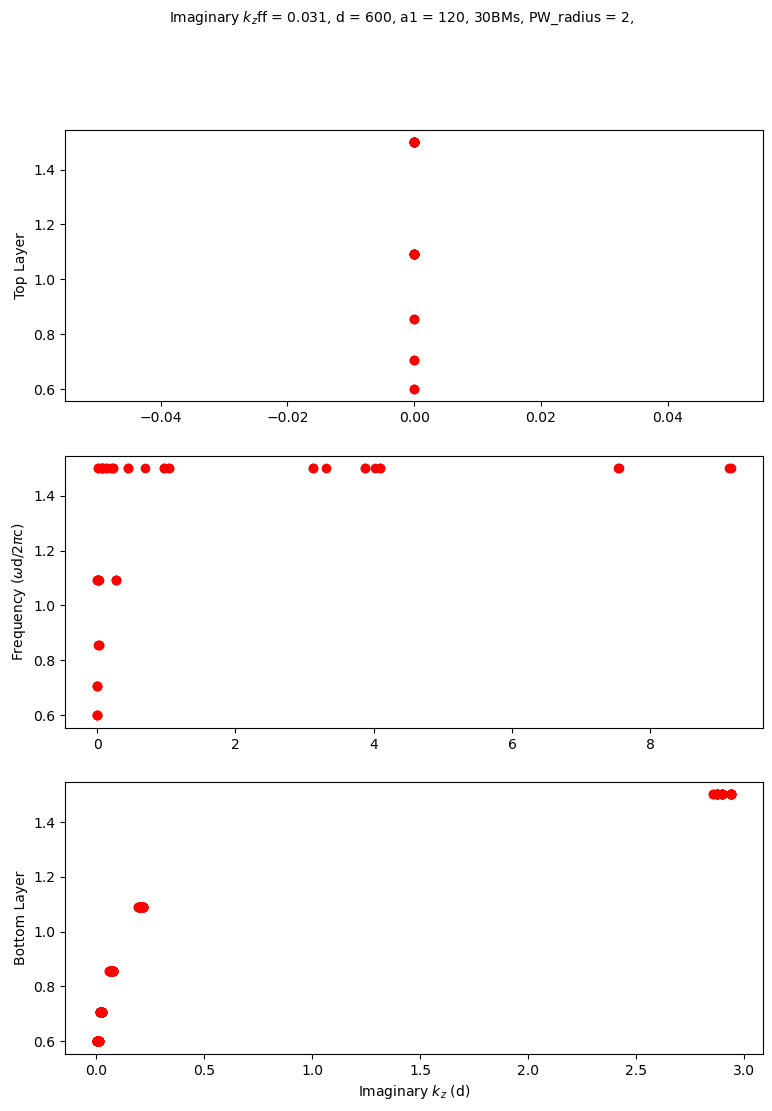

In [3]:
# Compute solar spectrum-weighted metrics
out = plotting.t_r_a_plots(stacks_list, ult_eta=True, J_sc=True, save_pdf=False, save_txt=False)
print("Spectra and Photovoltaic Metrics evaluated successfully.")

fig_omega = plotting.omega_plot(stacks_list, save_pdf=False)
plt.show()


## Physical Interpretation
- Nanowire arrays demonstrate broadband absorption enhancement over flat silicon slabs due to excitation of guided Bloch modes.
- The dispersion diagram illustrates band crossings and anti-crossings corresponding to leaky optical resonances.
